# 01 — Exploratory Data Analysis
Walmart weekly sales, 45 stores × 81 departments, 2010-02-05 … 2012-10-26.

In [1]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from forecast.data import load_raw, build_panel, MARKDOWNS
sns.set_theme(style='whitegrid')
train, stores, features = load_raw()
panel = build_panel(train, stores, features)
train.shape, stores.shape, features.shape

((421570, 5), (45, 3), (8190, 12))

## Data quality

In [2]:
L = train.groupby(['Store','Dept']).size()
print('series:', len(L), '| full 143 weeks:', (L == 143).sum(), '| < 52 weeks:', (L < 52).sum())
print('missing weeks filled on grid:', panel['Weekly_Sales'].isna().sum())
neg = train[train.Weekly_Sales < 0]
print('negative sales rows:', len(neg), f'({len(neg)/len(train):.2%})', '| top depts:', neg.Dept.value_counts().head(5).to_dict())

series: 3331 | full 143 weeks: 2660 | < 52 weeks: 340
missing weeks filled on grid: 54763
negative sales rows: 1285 (0.30%) | top depts: {47: 254, 18: 180, 54: 146, 19: 87, 94: 77}


## Total sales over time — holiday spikes
The biggest week is the one *before* the flagged Christmas week.

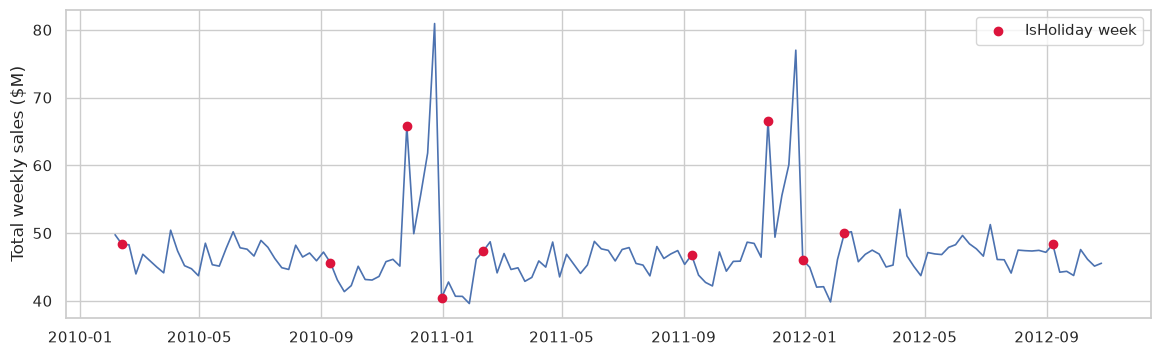

,sales,hol
Date,,
2010-12-24,80.9,False
2011-12-23,77.0,False
2011-11-25,66.6,True
2010-11-26,65.8,True
2010-12-17,61.8,False
2011-12-16,60.1,False


In [3]:
w = train.groupby('Date').agg(sales=('Weekly_Sales','sum'), hol=('IsHoliday','max'))
fig, ax = plt.subplots(figsize=(14,4))
ax.plot(w.index, w.sales/1e6, lw=1.2)
ax.scatter(w.index[w.hol], w.sales[w.hol]/1e6, color='crimson', zorder=3, label='IsHoliday week')
ax.set_ylabel('Total weekly sales ($M)'); ax.legend(); plt.show()
w.sort_values('sales', ascending=False).head(6).assign(sales=lambda d: (d.sales/1e6).round(1))

## Seasonality by week of year (each year overlaid)

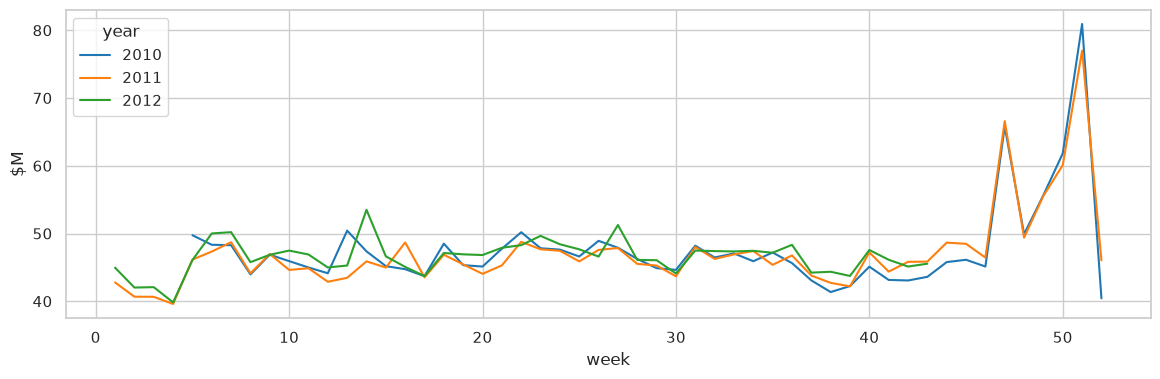

In [4]:
t = w.reset_index(); t['week'] = t.Date.dt.isocalendar().week; t['year'] = t.Date.dt.year
plt.figure(figsize=(14,4)); sns.lineplot(data=t, x='week', y=t.sales/1e6, hue='year', palette='tab10')
plt.ylabel('$M'); plt.show()

## Store type and size

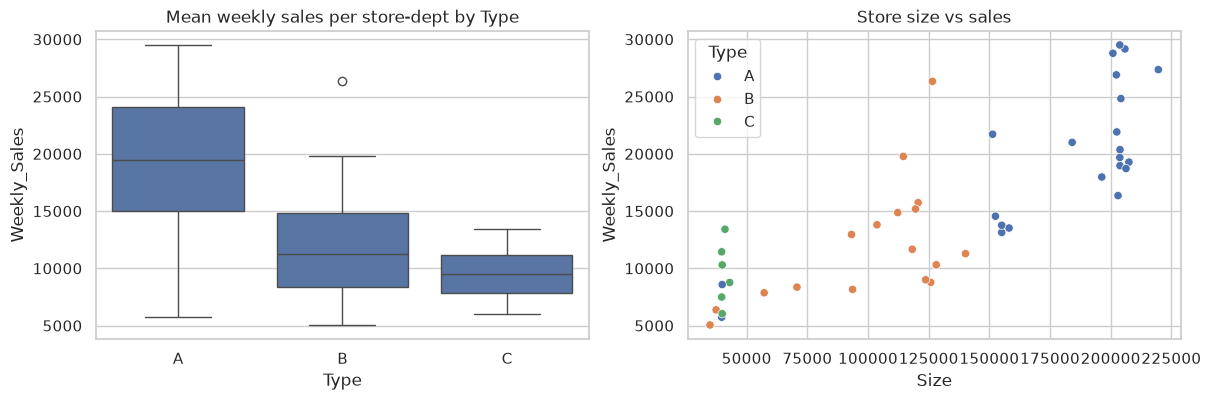

In [5]:
s = train.merge(stores, on='Store').groupby(['Store','Type','Size']).Weekly_Sales.mean().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.boxplot(data=s, x='Type', y='Weekly_Sales', ax=ax[0]); ax[0].set_title('Mean weekly sales per store-dept by Type')
sns.scatterplot(data=s, x='Size', y='Weekly_Sales', hue='Type', ax=ax[1]); ax[1].set_title('Store size vs sales')
plt.show()

## Departments — sales are concentrated in a few

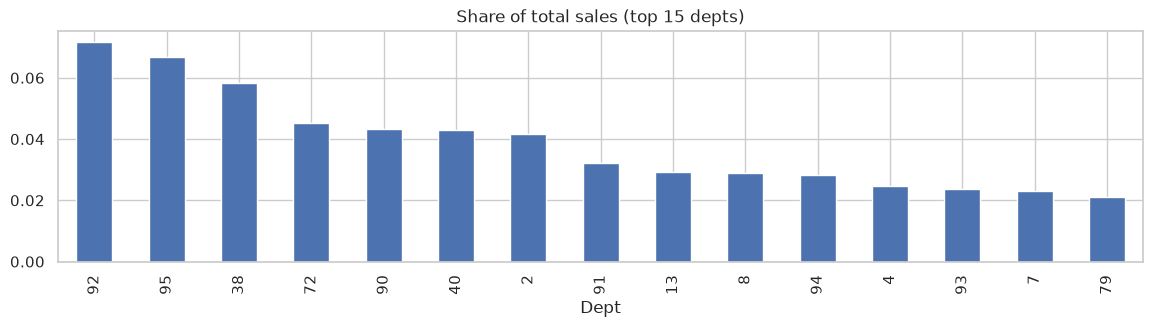

In [6]:
d = train.groupby('Dept').Weekly_Sales.sum().sort_values(ascending=False)
(d / d.sum()).head(15).plot.bar(figsize=(14,3), title='Share of total sales (top 15 depts)'); plt.show()

## Markdowns — only available from 2011-11-11

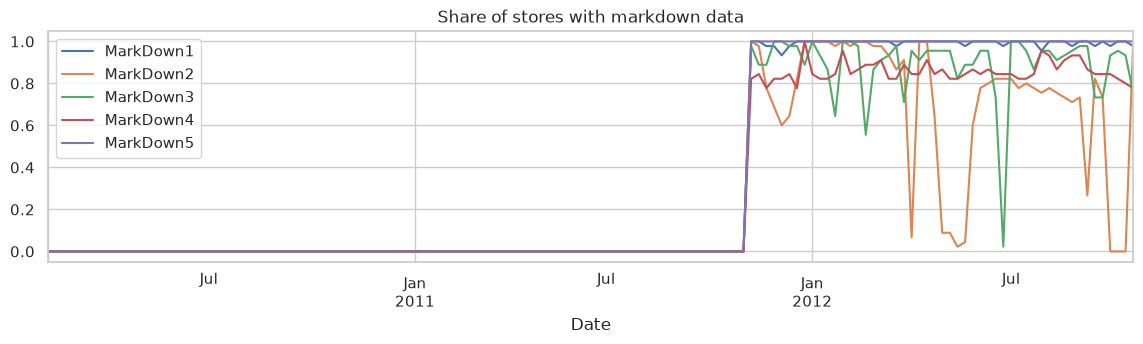

In [7]:
f = features[features.Date <= '2012-10-26']
f.groupby('Date')[MARKDOWNS].apply(lambda x: x.notna().mean()).plot(figsize=(14,3), title='Share of stores with markdown data')
plt.show()

In [8]:
m = train.merge(features, on=['Store','Date','IsHoliday'])
m = m[m.Date >= '2011-11-11']
m[['Weekly_Sales', *MARKDOWNS]].corr()['Weekly_Sales'].round(3)

Weekly_Sales    1.000
MarkDown1       0.085
MarkDown2       0.024
MarkDown3       0.060
MarkDown4       0.045
MarkDown5       0.090
Name: Weekly_Sales, dtype: float64